# UPMaBoSS: sensitivity to the update time

This notebook complements the [UPMaBoSS cell fate notebook](CellFateModel_uppmaboss.ipynb) of the
[MaBoSS website](https://maboss.curie.fr).

With UPMaBoSS, the population is updated at regular intervals: the update time is set by `max_time` in the
configuration file, and the number of updates by `steps` in the update file. This update time cannot be set
from biological considerations: it should be smaller than the first transient effect, and the sensitivity of the
results to its value should be studied. We do so for the cell fate model, with a transient TNF activation and
without TNF.

**Requirements:** [pyMaBoSS](https://pymaboss.readthedocs.io/), and the files `CellFateModel_uppmaboss.bnd`,
`CellFateModel_uppmaboss.cfg` and `CellFateModel_uppmaboss.upp`, in the same folder as this notebook.

In [1]:
import math
import os
import maboss
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.offsetbox import HPacker

# The figures are saved in the "figures" folder
os.makedirs("figures", exist_ok=True)
plt.rcParams.update({"savefig.dpi": 150, "savefig.bbox": "tight", "figure.constrained_layout.use": True})

def legend_below():
    """Move the legend of the current figure below the plot, in centered rows of similar widths."""
    figure, legend = plt.gcf(), plt.gca().get_legend()
    handles, labels = legend.legend_handles, [text.get_text() for text in legend.get_texts()]
    legend.remove()
    legend = figure.legend(handles, labels, loc="outside lower center", ncols=1)
    # Matplotlib fills the rows from the left: we rearrange the entries of the legend in centered rows,
    # as few as possible within the width of the plot, and of similar widths
    column = legend._legend_handle_box.get_children()[0]
    entries, column.align = column.get_children(), "center"
    sep = legend.columnspacing * legend.prop.get_size_in_points() * figure.dpi / 72
    widths = [entry.get_bbox(figure.canvas.get_renderer()).width + sep for entry in entries]
    max_width = 0.8 * figure.get_figwidth() * figure.dpi
    for n_rows in range(math.ceil(sum(widths) / max_width), len(entries) + 1):
        rows, row_widths = [[]], [0]
        for entry, width in zip(entries, widths):
            if rows[-1] and row_widths[-1] + width / 2 > sum(widths) / n_rows:
                rows.append([])
                row_widths.append(0)
            rows[-1].append(entry)
            row_widths[-1] += width
        if max(row_widths) <= max_width:
            break
    column._children = [HPacker(sep=sep, align="baseline", children=row) for row in rows]

In [2]:
upp_file = "CellFateModel_uppmaboss.upp"
model_WT = maboss.load("CellFateModel_uppmaboss.bnd", "CellFateModel_uppmaboss.cfg")
model_noTNF = model_WT.copy()
model_noTNF.network.set_istate("TNF", [1, 0])

## First transient effects

We first run MaBoSS simulations over 48 hours, without taking into account cell death and division, to find the
first transient effects.

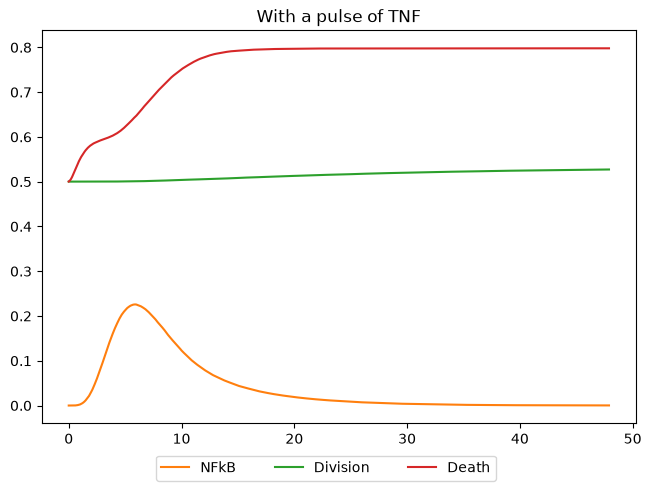

In [3]:
model_48h = maboss.copy_and_update_parameters(model_WT, {"max_time": 48})
model_48h.network.set_output(("Death", "Division", "NFkB"))
model_48h.run().plot_node_trajectory()
plt.title("With a pulse of TNF")
legend_below()
plt.savefig("figures/upmaboss_timestep_maboss_tnf.png")

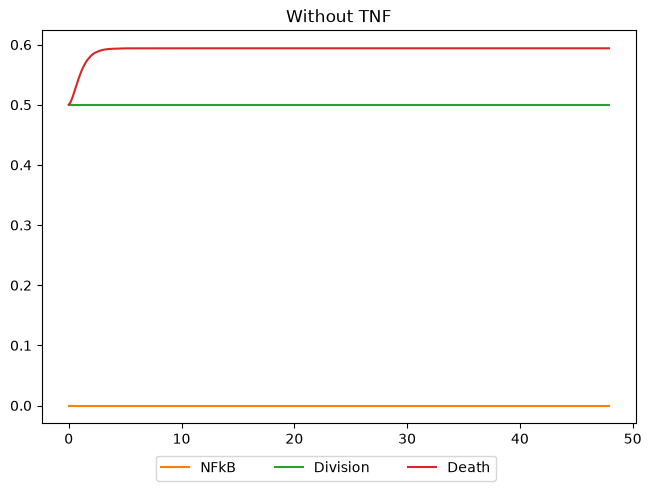

In [4]:
model_48h = maboss.copy_and_update_parameters(model_noTNF, {"max_time": 48})
model_48h.network.set_output(("Death", "Division", "NFkB"))
model_48h.run().plot_node_trajectory()
plt.title("Without TNF")
legend_below()
plt.savefig("figures/upmaboss_timestep_maboss_notnf.png")

With TNF, the first local extremum occurs at t = 1 hour. Without TNF, the asymptotic behaviour is reached very
fast, and the probabilities vary very little (NFκB stays inactive). In both cases, the update time should be at
most 1 hour.

## UPMaBoSS simulations with different update times

We run UPMaBoSS with update times of 1, 1/2, 1/3 and 1/4 hour, keeping a total time of 48 hours: the duration
of each step (`max_time` and `time_tick`) is divided, and the number of steps multiplied, by the same number.

In [5]:
max_time = float(model_WT.param["max_time"])
time_tick = float(model_WT.param["time_tick"])

def population_ratios(model, divisor, name):
    model_step = maboss.copy_and_update_parameters(model, {"max_time": max_time / divisor,
                                                           "time_tick": time_tick / divisor})
    upp = maboss.UpdatePopulation(model_step, upp_file)
    upp.setStepNumber(48 * divisor)
    return upp.run(f"{name}_R{divisor}").get_population_ratios(f"Update time = 1/{divisor} h")

ratios_WT = [population_ratios(model_WT, d, "WT") for d in [1, 2, 3, 4]]
ratios_noTNF = [population_ratios(model_noTNF, d, "noTNF") for d in [1, 2, 3, 4]]

The population ratios of the different update times are given at different time points: we plot them one by one.

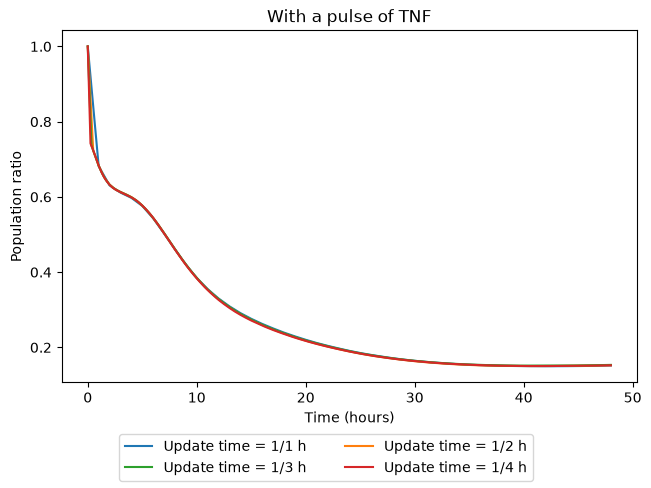

In [6]:
plt.figure()
for ratios in ratios_WT:
    ratios.plot(legend=True, title="With a pulse of TNF", xlabel="Time (hours)", ylabel="Population ratio")
legend_below()
plt.savefig("figures/upmaboss_timestep_tnf.png")

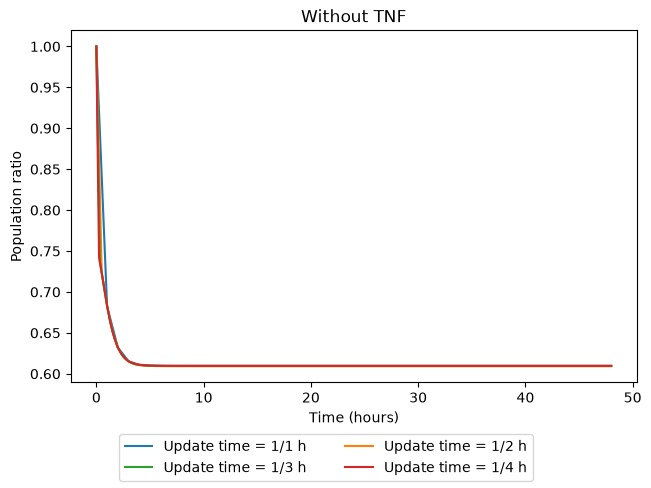

In [7]:
plt.figure()
for ratios in ratios_noTNF:
    ratios.plot(legend=True, title="Without TNF", xlabel="Time (hours)", ylabel="Population ratio")
legend_below()
plt.savefig("figures/upmaboss_timestep_notnf.png")

With or without TNF, the population dynamics are robust: the different update times give almost identical
population ratios, the shortest update times only resolving more finely the first hours.